# 03 - Volume of Clay (Vcl)

**Part A - Petrophys Curriculum - Foundations**

The volume of clay (Vcl, sometimes written Vsh for volume of shale) is one of the
most consequential intermediate curves in a petrophysical interpretation. It drives
the split between *total* and *effective* porosity, controls the shale term in every
shaly-sand saturation model, and defines the net-reservoir flag. Getting Vcl wrong
propagates into every downstream number.

This lesson builds Vcl from the ground up using `petrophys.interpretation.clay_volume`.

## Learning goals

By the end of this lesson you will be able to:

- Compute the **linear gamma-ray index** (IGR) and the four common **non-linear GR
  corrections** (Larionov tertiary, Larionov older, Steiber, Clavier) with
  `vcl_from_gr`.
- **Pick GR endpoints** (`GR_clean`, `GR_clay`) objectively from percentiles of the
  log rather than by eye.
- Explain *why* the non-linear transforms exist: the linear index systematically
  **over-estimates** clay, and Larionov-type curves pull it back down.
- Estimate Vcl from the **SP** log (`vcl_from_sp`) and from **neutron density**
  (`vcl_from_nd`, the closed-form 3-point equation), and understand when each is valid.
- Combine methods with `calculate_vcl` and estimate **clay resistivity** with
  `calculate_rcl`.
- Classify the result with `classify_vcl`.

## Why this matters (the physics)

Clay minerals carry no effective (movable-fluid) porosity but are electrically
conductive and radioactive. Three independent log responses let us "see" clay:

| Indicator | Physical basis | Failure mode |
|-----------|----------------|--------------|
| **Gamma ray** | Clays concentrate K, U, Th | Misreads radioactive sands (feldspar, mica) or non-radioactive kaolinite |
| **SP** | Membrane potential between shale and permeable sand | Suppressed by fresh formation water (Rmf ~ Rw), thin beds, KCl/OBM |
| **Neutron-Density** | Clay-bound water raises NPHI while density stays high | Distorted by gas (crossover) |

Because each has a different blind spot, robust workflows compute several and combine
them - which is exactly what `calculate_vcl` does internally.

### The gamma-ray index

The starting point for every GR method is the linear **gamma-ray index**:

$$ I_{GR} = \frac{GR - GR_{clean}}{GR_{clay} - GR_{clean}} $$

Taking $V_{cl} = I_{GR}$ (the *linear* method) assumes clay content is proportional
to radioactivity. In reality the relationship is concave - a little clay raises GR a
lot - so the linear index **over-states** clay. The non-linear equations correct for
this.

### Prerequisites

This lesson assumes you have worked through **lesson 01 (data access)** and
**lesson 02 (quality control)**. We use the bundled clastic well **30/6-5** from
the GEOLINK dataset (depths in metres).

In [1]:
%matplotlib inline
from petrophys.visualization import use_plot_style
use_plot_style()
import matplotlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import petrophys
from petrophys.io import read_las

print('petrophys', petrophys.__version__)
print('geolink samples:', petrophys.list_samples('geolink'))

petrophys 3.0.0
geolink samples: ['15_9-14', '16_7-1', '25_5-1', '30_6-5']


In [2]:
# Load the teaching well and pull the curves we need for clay volume.
well = read_las(petrophys.sample('30_6-5'))
print('Well      :', well.name)
print('Samples   :', well.n_samples)
print('Depth unit:', well.depth_unit)
print('Depth span: %.1f - %.1f %s' % (well.start_depth, well.stop_depth, well.depth_unit))

for mnem in ['GR', 'SP', 'RHOB', 'NPHI', 'RDEP']:
    print('  has %-5s -> %s' % (mnem, well.has_curve(mnem)))

depth = well.depth
gr   = well.get('GR').data
sp   = well.get('SP').data
rhob = well.get('RHOB').data
nphi = well.get('NPHI').data
rdep = well.get('RDEP').data

Well      : 30/6-5
Samples   : 22176
Depth unit: m
Depth span: 176.6 - 3556.1 m
  has GR    -> True
  has SP    -> True
  has RHOB  -> True
  has NPHI  -> True
  has RDEP  -> True


## Step 1 - Picking the GR endpoints objectively

`GR_clean` (clean-sand baseline) and `GR_clay` (pure-shale reading) are the two most
important parameters in a GR clay model. Reading them off a plot by eye is subjective
and hard to reproduce. A robust, defensible choice is to use **percentiles** of the
GR log:

- `GR_clean` = a **low** percentile (P5): the cleanest sands in the interval.
- `GR_clay`  = a **high** percentile (P95): the most shale-rich beds.

Using P5/P95 rather than the absolute min/max rejects spikes and washout artefacts.

In [3]:
gr_valid = gr[np.isfinite(gr)]

gr_clean = np.percentile(gr_valid, 5)    # clean-sand baseline
gr_clay  = np.percentile(gr_valid, 95)   # pure-shale reading

print('GR statistics (API):')
print('  min   : %6.1f' % gr_valid.min())
print('  P5    : %6.1f  <- GR_clean' % gr_clean)
print('  median: %6.1f' % np.median(gr_valid))
print('  P95   : %6.1f  <- GR_clay' % gr_clay)
print('  max   : %6.1f' % gr_valid.max())

GR statistics (API):
  min   :  -12.6
  P5    :   21.6  <- GR_clean
  median:   53.3
  P95   :  115.3  <- GR_clay
  max   :  238.0


> **Note on `vcl_from_gr` internals.** The library enforces industry guard-rails:
> it forces `GR_clay >= 100` and `GR_clean <= 20` API before computing the index
> (a clean sand should not read above ~20, a shale not below ~100). So even if our
> percentiles land inside that band, the effective endpoints used are
> `min(GR_clean, 20)` and `max(GR_clay, 100)`. We print both so there are no
> surprises.

In [4]:
gr_clean_eff = min(gr_clean, 20.0)
gr_clay_eff  = max(gr_clay, 100.0)
print('Effective endpoints used by vcl_from_gr:')
print('  GR_clean_eff = %.1f API' % gr_clean_eff)
print('  GR_clay_eff  = %.1f API' % gr_clay_eff)

Effective endpoints used by vcl_from_gr:
  GR_clean_eff = 20.0 API
  GR_clay_eff  = 115.3 API


## Step 2 - The five GR methods, side by side

`vcl_from_gr(gr, gr_min, gr_max, method=...)` accepts:

| `method` | Equation | Use when |
|----------|----------|----------|
| `linear` | $V_{cl}=I_{GR}$ | Quick-look; **over-estimates** clay |
| `larionov_tertiary` | $0.083\,(2^{3.7 I_{GR}}-1)$ | Young, unconsolidated (Tertiary) rocks |
| `larionov_older` | $0.33\,(2^{2 I_{GR}}-1)$ | Older, consolidated / Mesozoic rocks |
| `steiber` | $I_{GR}/(3-2 I_{GR})$ | General clastic correction |
| `clavier` | $1.7-\sqrt{3.38-(I_{GR}+0.7)^2}$ | General clastic correction |

All four non-linear curves lie **below** the linear line for the same GR - they
reduce the clay over-estimate. Let us compute all five over the whole well.

In [5]:
from petrophys.interpretation.clay_volume import vcl_from_gr

methods = ['linear', 'larionov_tertiary', 'larionov_older', 'steiber', 'clavier']
vcl_gr = {m: vcl_from_gr(gr, gr_clean, gr_clay, method=m) for m in methods}

print('Whole-well mean Vcl by GR method:')
for m in methods:
    print('  %-18s : %.3f' % (m, np.nanmean(vcl_gr[m])))


Whole-well mean Vcl by GR method:
  linear             : 0.405
  larionov_tertiary  : 0.227
  larionov_older     : 0.296
  steiber            : 0.248
  clavier            : 0.282


#### Interpretation

Every nonlinear transform gives a lower mean Vcl than the linear gamma-ray
index. This is the expected correction when the linear index overstates clay
volume.


### Overlay: transfer functions (Vcl vs IGR)

The clearest way to see the differences is to plot each method as a function of the
underlying linear index $I_{GR}$ over its full range 0 -> 1. The linear method is the
45-degree line; the corrections all bow beneath it.

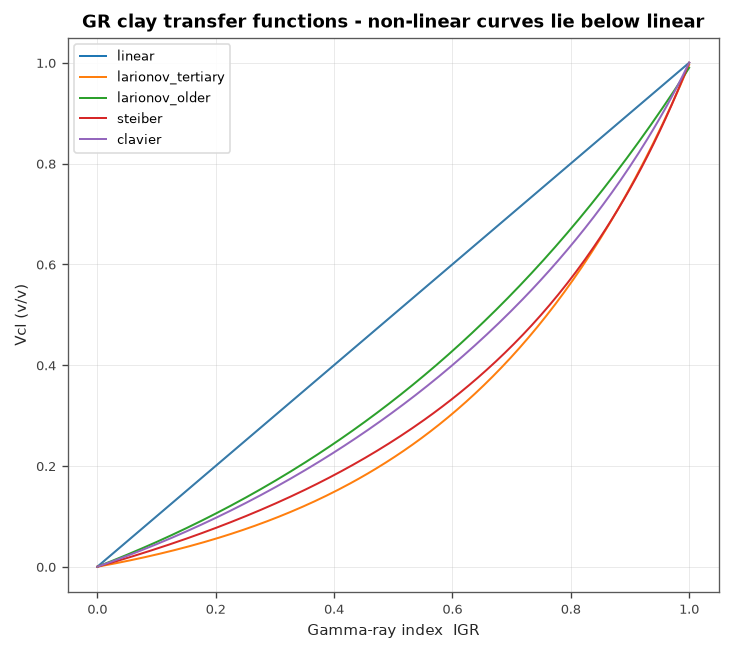

In [6]:
from petrophys.interpretation.clay_volume import (vcl_linear, vcl_larionov_tertiary,
                                    vcl_larionov_older, vcl_steiber, vcl_clavier)
from petrophys.visualization import create_line_comparison

igr = np.linspace(0, 1, 200)
transfer = {
    'linear'           : igr,
    'larionov_tertiary': vcl_larionov_tertiary(igr),
    'larionov_older'   : vcl_larionov_older(igr),
    'steiber'          : vcl_steiber(igr),
    'clavier'          : vcl_clavier(igr),
}

fig, ax = create_line_comparison(
    igr, transfer, figsize=(7, 6),
    xlabel='Gamma-ray index  IGR', ylabel='Vcl (v/v)',
    title='GR clay transfer functions - non-linear curves lie below linear')
ax.plot([0, 1], [0, 1], color='grey', lw=0.6, alpha=0.4)  # 1:1 reference
plt.show()

**Reading the plot.** For a mid-range reading of $I_{GR}=0.5$, the linear method
returns Vcl = 0.50, but Larionov-tertiary returns roughly 0.22 and Steiber roughly
0.25. That is a large difference in a shaly sand: it can move an interval from
"non-reservoir" to "pay". Larionov *tertiary* is the most aggressive correction
(steepest curvature) and is appropriate for young, poorly consolidated sediments;
Larionov *older* is milder and suits consolidated rocks.

### Depth overlay and a numeric table

Now the same methods plotted against depth over a shaly-sand interval, plus a table
of the resulting Vcl at a handful of depths so the differences are concrete.

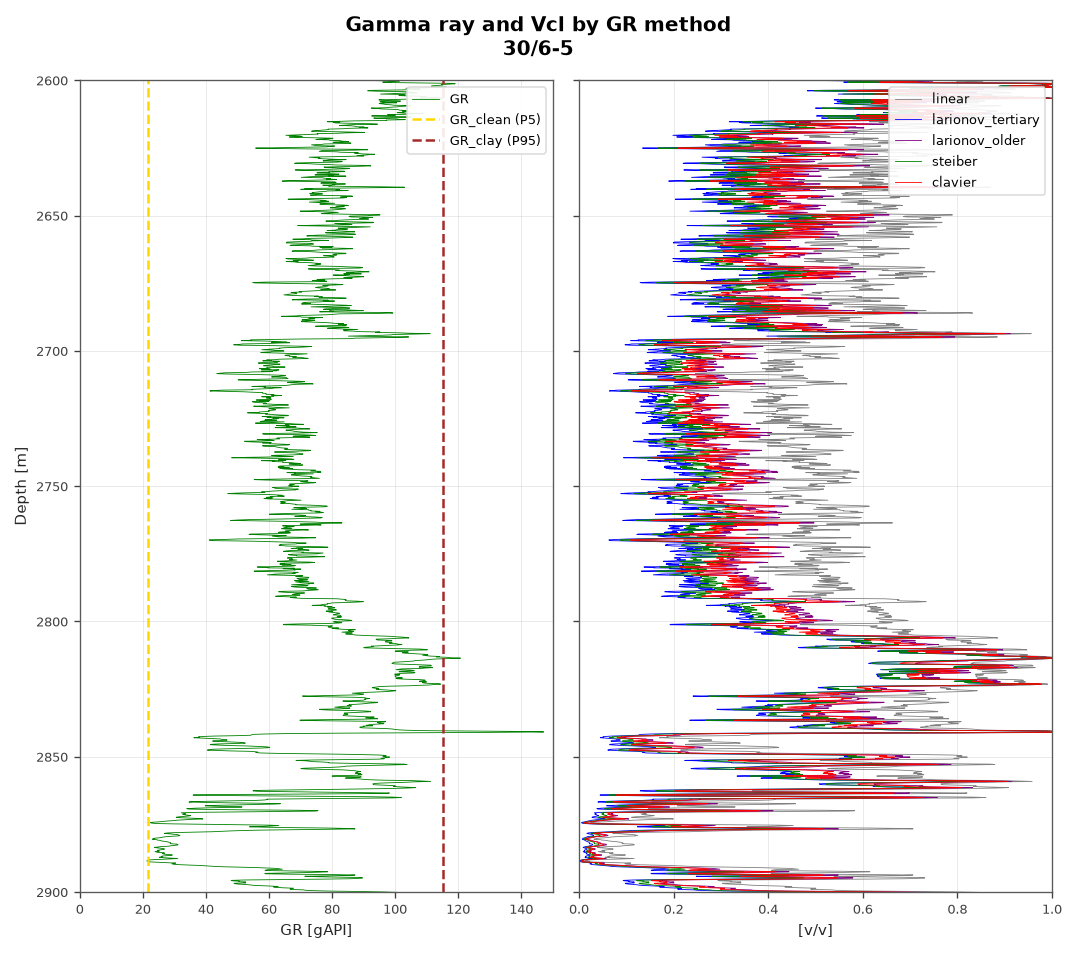

In [7]:
# A depth window that contains both clean sand and shale.
from petrophys.visualization import LogPlot

top, base = 2600.0, 2900.0
sel = (depth >= top) & (depth <= base)

# Attach each GR-method Vcl to the well so LogPlot can render them.
for m in methods:
    if not well.has_curve('VCL_GR_' + m.upper()):
        well.add_curve('VCL_GR_' + m.upper(), vcl_gr[m], unit='v/v',
                       description='Vcl from GR (%s)' % m)

lp = LogPlot(well, figsize=(9, 8))
lp.create_figure(n_tracks=2)

# Track 0: gamma ray with clean/clay endpoints marked on the returned axis.
lp.add_curve(0, 'GR', color='green', xlim=(0, 150))
lp.axes[0].axvline(gr_clean, color='gold', ls='--', label='GR_clean (P5)')
lp.axes[0].axvline(gr_clay, color='brown', ls='--', label='GR_clay (P95)')
lp.axes[0].legend(fontsize=8, loc='upper right')

# Track 1: Vcl by GR method.
colors = {'linear': 'grey', 'larionov_tertiary': 'blue',
          'larionov_older': 'purple', 'steiber': 'green', 'clavier': 'red'}
for m in methods:
    lp.add_curve(1, 'VCL_GR_' + m.upper(), color=colors[m], xlim=(0, 1), label=m)

lp.set_depth_range(top, base)
lp.add_title('Gamma ray and Vcl by GR method')
lp.show()

In [8]:
# Numeric table at five representative depths inside the window.
sample_depths = np.linspace(top + 20, base - 20, 5)
rows = []
for d in sample_depths:
    idx = int(np.argmin(np.abs(depth - d)))
    row = {'Depth_m': round(float(depth[idx]), 1), 'GR_API': round(float(gr[idx]), 1)}
    for m in methods:
        row[m] = round(float(vcl_gr[m][idx]), 3)
    rows.append(row)

table = pd.DataFrame(rows)
print(table.to_string(index=False))


 Depth_m  GR_API  linear  larionov_tertiary  larionov_older  steiber  clavier
  2620.0    72.1   0.546              0.254           0.374    0.286    0.348
  2685.0    86.0   0.692              0.407           0.532    0.429    0.500
  2750.0    69.5   0.519              0.231           0.348    0.265    0.324
  2815.0   101.9   0.859              0.668           0.756    0.670    0.726
  2880.0    24.8   0.050              0.011           0.024    0.017    0.021


#### Reading the table

The linear method is highest at each sampled depth. The nonlinear corrections
systematically reduce Vcl, while their relative ordering depends on IGR and the
assumed rock age.


## Step 3 - Clay volume from SP

The SP log gives an independent clay indicator via the shale-fraction of the SP
deflection:

$$ V_{cl}^{SP} = \frac{SP_{clean} - SP}{SP_{clean} - SP_{shale}} $$

`vcl_from_sp(sp, sp_max, sp_min)` implements this, where `sp_max` is the **clean-sand**
deflection (the most negative excursion, the "SSP" line) and `sp_min` is the **shale
baseline**. We pick them from percentiles again: P5 (most negative) for clean sand,
P95 for the shale line.

**Caveat:** SP is unreliable with fresh formation water, KCl / oil-based mud, or in
thin beds. Treat it as a cross-check, not a primary curve.

In [9]:
from petrophys.interpretation.clay_volume import vcl_from_sp

sp_valid = sp[np.isfinite(sp)]
sp_clean = np.percentile(sp_valid, 5)    # most negative -> clean sand (SSP)
sp_shale = np.percentile(sp_valid, 95)   # shale baseline
print('SP_clean (P5, clean sand): %.1f mV' % sp_clean)
print('SP_shale (P95, baseline) : %.1f mV' % sp_shale)

vcl_sp = vcl_from_sp(sp, sp_max=sp_clean, sp_min=sp_shale)
print('Vcl_SP whole-well mean   : %.3f' % np.nanmean(vcl_sp))

SP_clean (P5, clean sand): 43.2 mV
SP_shale (P95, baseline) : 111.6 mV
Vcl_SP whole-well mean   : 0.265


## Step 4 - Clay volume from neutron density (the 3-point equation)

In a water-bearing shaly sand, clay-bound water pushes the **neutron** porosity up
while **density** stays high, so shale plots away from the clean sandstone line.
`vcl_from_nd` is a closed-form equation evaluated at every sample: it returns the
fractional distance of the (NPHI, RHOB) pair from the clean line toward a defined
clay point in density-neutron space. Nothing is read off a plot; the three
endpoints fully determine the result.

For a clastic well we want the **sandstone** clean line. The module ships the correct
endpoints via `nd_clean_line('sandstone')`; we pass all three points (the clean line
plus the clay point) explicitly so the lesson is self-documenting.

The clay point below is the default of `vcl_from_nd` (and of `VclModule`): RHOB
2.62 g/cm3, NPHI 0.38. `pp.interpret` does not use a fixed point. It picks the clay
point in the well's own good-hole shales - the median RHOB and NPHI of at least 20
shale-lithology samples, else of the samples with VCL_GR > 0.9, else the default -
and `nd_clay=(RHOB, NPHI)` sets it yourself. A point less than 0.10 v/v of neutron
above the clean line cannot tell shale from clean rock, so VCL_ND is then reported
but left out of VCL, with a warning. The workflow also leaves VCL_ND undefined where
the neutron reads above both the clean line's 40 p.u. end point and the clay point:
outside the triangle the three-point formula interpolates in, where undercompacted
mudstone often plots. For your own picks, `nd_shale_point(nphi, rhob, shale,
matrix=...)` in `petrophys.interpretation.clay_volume.nd_method` returns the median
shale point of the samples you flag (Crain, *The Log Analysis Handbook*, 1986).

In [10]:
from petrophys.interpretation.clay_volume import vcl_from_nd
from petrophys.interpretation.clay_volume.nd_method import nd_clean_line

den_cl1, neu_cl1, den_cl2, neu_cl2 = nd_clean_line('sandstone')
print('Sandstone clean line endpoints:')
print('  Cl1 (matrix)      : RHOB=%.2f, NPHI=%+.2f' % (den_cl1, neu_cl1))
print('  Cl2 (~40 pu water): RHOB=%.2f, NPHI=%+.2f' % (den_cl2, neu_cl2))
print('  Clay point        : RHOB=2.62, NPHI=+0.38 (library default)')

vcl_nd = vcl_from_nd(nphi, rhob,
                     den_cl1=den_cl1, neu_cl1=neu_cl1,
                     den_cl2=den_cl2, neu_cl2=neu_cl2,
                     den_clay=2.62, neu_clay=0.38)
print('Vcl_ND whole-well mean : %.3f' % np.nanmean(vcl_nd))

Sandstone clean line endpoints:
  Cl1 (matrix)      : RHOB=2.65, NPHI=-0.02
  Cl2 (~40 pu water): RHOB=1.99, NPHI=+0.38
  Clay point        : RHOB=2.62, NPHI=+0.38 (library default)
Vcl_ND whole-well mean : 0.443


### Comparing the three families

We now have three independent clay estimates over the window: GR (Larionov older, a
sensible default for this Jurassic clastic), SP, and N-D. Overlaying them shows how
well they agree and where they diverge.

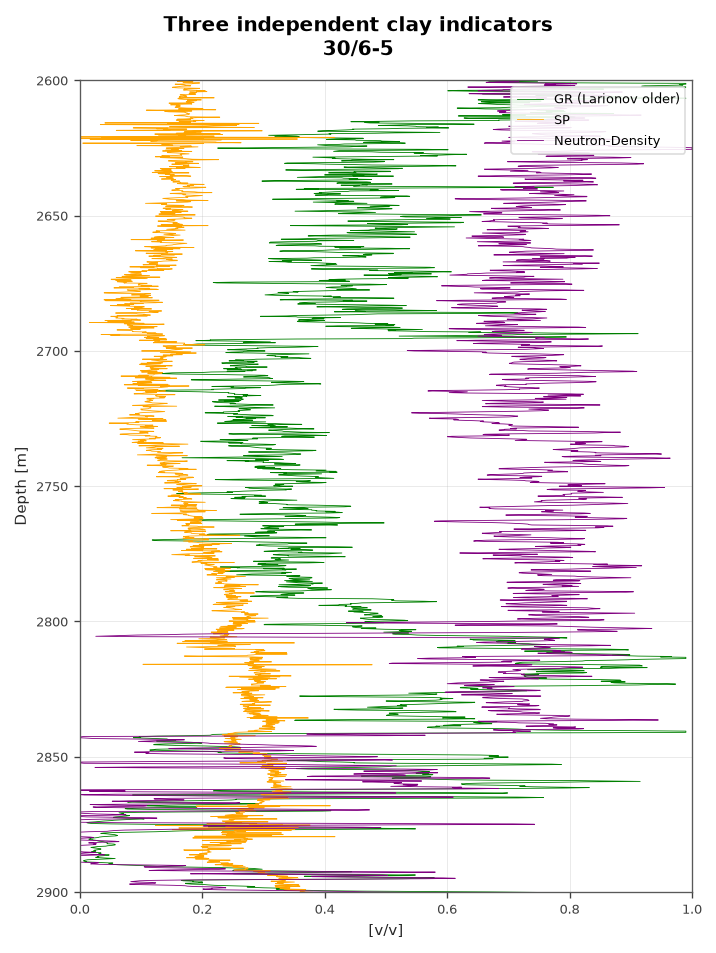

Window mean Vcl: GR=0.419  SP=0.196  ND=0.640


In [11]:
from petrophys.visualization import LogPlot

vcl_gr_ref = vcl_gr['larionov_older']

# Attach the SP and ND clay volumes to the well.
well.add_curve('VCL_SP', vcl_sp, unit='v/v', description='Vcl from SP')
well.add_curve('VCL_ND', vcl_nd, unit='v/v', description='Vcl from neutron-density')

lp = LogPlot(well, figsize=(6, 8))
lp.create_figure(n_tracks=1)
lp.add_curve(0, 'VCL_GR_LARIONOV_OLDER', color='green', xlim=(0, 1),
             label='GR (Larionov older)')
lp.add_curve(0, 'VCL_SP', color='orange', xlim=(0, 1), label='SP')
lp.add_curve(0, 'VCL_ND', color='purple', xlim=(0, 1), label='Neutron-Density')
lp.set_depth_range(top, base)
lp.add_title('Three independent clay indicators')
lp.show()

print('Window mean Vcl: GR=%.3f  SP=%.3f  ND=%.3f'
      % (np.nanmean(vcl_gr_ref[sel]), np.nanmean(vcl_sp[sel]), np.nanmean(vcl_nd[sel])))

## Step 5 - Combining methods with `calculate_vcl`

The high-level `calculate_vcl(well, ...)` runs all applicable methods and combines
them. Two combine rules are available:

- `combine='min'` (default): the **minimum** across methods at each depth. Simple and
  conservative, but a spuriously low SP or GR can drag the estimate below the true
  clay content.
- `combine='auto'`: neutron-density-primary, using GR where gas invalidates N-D or
  where N-D is unavailable, and SP only as a non-lowering cross-check. Recommended
  for clastics. The next cell counts which of the two reasons sent each sample to GR.

The returned `VclResult` exposes `vcl` (final), the per-method arrays `vcl_gr`,
`vcl_sp`, `vcl_nd`, and `method_used` (which method won at each depth).

**What `pp.interpret` does.** The workflow also takes a minimum, but of the
gamma-ray and neutron-density estimates only. VCL_ND is measured from the clean
line of the run's matrix (sandstone in the default clastic domain) with the clay
point picked in the well's shales (Step 4). VCL_SP is computed and reported, but it
joins the minimum only when you set both SP baselines, `sp_min` (shale) and
`sp_max` (clean sand), for an SP without baseline drift; otherwise it only fills
depths with no gamma-ray or neutron-density value. Constant baselines picked over a
whole log mostly measure the drift of the SP baseline (lesson 06 shows it on this
well), not shaliness.

In [12]:
from petrophys.interpretation.clay_volume import calculate_vcl

res_min  = calculate_vcl(well, gr_method='larionov_older', matrix='sandstone',
                         combine='min')
res_auto = calculate_vcl(well, gr_method='larionov_older', matrix='sandstone',
                         combine='auto')

print('Final Vcl mean  (min ) : %.3f' % np.nanmean(res_min.vcl))
print('Final Vcl mean  (auto) : %.3f' % np.nanmean(res_auto.vcl))

for rule, res in [('min', res_min), ('auto', res_auto)]:
    used, counts = np.unique(res.method_used.astype(str), return_counts=True)
    print()
    print("Which method won under combine='%s':" % rule)
    for u, c in zip(used, counts):
        print('  %-5s : %6d samples (%.1f%%)' % (u, c, 100.0 * c / well.n_samples))

gr_won = res_auto.method_used.astype(str) == 'GR'
nd_missing = ~(np.isfinite(nphi) & np.isfinite(rhob))
print()
print("combine='auto' used GR where N-D input is missing: %6d samples" % np.sum(gr_won & nd_missing))
print("combine='auto' used GR where N-D is gas-affected : %6d samples" % np.sum(gr_won & ~nd_missing))

Final Vcl mean  (min ) : 0.124
Final Vcl mean  (auto) : 0.379

Which method won under combine='min':
  GR    :  10071 samples (45.4%)
  ND    :   2068 samples (9.3%)
  SP    :  10037 samples (45.3%)

Which method won under combine='auto':
  GR    :   4834 samples (21.8%)
  ND    :  17342 samples (78.2%)

combine='auto' used GR where N-D input is missing:   4760 samples
combine='auto' used GR where N-D is gas-affected :     74 samples


The `min` rule returns a noticeably lower whole-well clay volume: at most depths the
lower of the GR and SP estimates wins and the neutron-density estimate rarely does, so
the combined curve is pulled down. The `auto` rule anchors on the neutron-density
response, which is the more physically trustworthy clay indicator in this
water/oil-bearing clastic, and falls back to GR mainly where the neutron log was not
run. This is a good illustration of why the combine rule is a real interpretation
decision, not a formality. It is also why `pp.interpret` keeps an SP with
whole-log baselines out of its minimum.

## Step 6 - Clay resistivity (Rcl)

Shaly-sand saturation models (Simandoux, Indonesia, dual-water) need a value for the
resistivity of the clay itself, `Rcl`. `calculate_rcl` estimates it from the **deep
resistivity** in near-pure-clay zones (default `vcl > 0.9`), returning a fallback of
5 ohm.m when no such zone exists.

In [13]:
from petrophys.interpretation.clay_volume import calculate_rcl

rcl = calculate_rcl(rdep, res_auto.vcl, vcl_threshold=0.9, statistic='median')
n_pure_clay = int(np.sum(np.isfinite(res_auto.vcl) & (res_auto.vcl > 0.9)))
print('Pure-clay samples (Vcl>0.9): %d' % n_pure_clay)
print('Estimated Rcl              : %.2f ohm.m' % rcl)
if n_pure_clay == 0:
    print('(no zone exceeded the 0.9 threshold -> the 5.0 ohm.m default was returned)')

Pure-clay samples (Vcl>0.9): 116
Estimated Rcl              : 3.64 ohm.m


## Step 7 - Classifying the result

`classify_vcl` bins the final clay volume into three formation-quality categories:

- `CLEAN_FORMATION` : Vcl < 0.25
- `MODERATE_CLAY`   : 0.25 <= Vcl <= 0.50
- `SHALY_FORMATION` : Vcl > 0.50

In [14]:
from petrophys.interpretation.clay_volume import classify_vcl

vcl_final = res_auto.vcl
labels = classify_vcl(vcl_final)                 # array of VclClassification enums
label_str = np.array([str(x).split('.')[-1] if x is not None else 'NaN' for x in labels])

finite = np.isfinite(vcl_final)
cats, counts = np.unique(label_str[finite], return_counts=True)
print('Formation-quality split (whole well, combine=auto):')
for c, n in zip(cats, counts):
    print('  %-18s : %6d samples (%.1f%%)' % (c, n, 100.0 * n / finite.sum()))

Formation-quality split (whole well, combine=auto):
  CLEAN_FORMATION    :   8726 samples (39.3%)
  MODERATE_CLAY      :   5859 samples (26.4%)
  SHALY_FORMATION    :   7591 samples (34.2%)


## Pitfalls and parameter choices

- **Endpoint picking dominates everything.** A 10-API error in `GR_clay` shifts the
  whole Vcl curve. Percentiles (P5/P95) give a reproducible first pass; refine against
  core or crossplots where available.
- **Linear GR over-estimates clay** - never ship a linear Vcl for volumetrics. Use
  Larionov (tertiary for young rocks, older for consolidated), Steiber, or Clavier.
- **SP is fragile.** Discard it with fresh water, KCl/oil-based mud, thin beds or a
  drifting baseline: constant baselines picked over the whole log misread every
  interval where the baseline has moved.
- **N-D is distorted by gas.** In gas zones the neutron reads *low*, so N-D
  under-estimates clay - this is exactly why `combine='auto'` falls back to GR there.
- **Combine rule matters.** `min` is conservative but can under-read; `auto` is the
  better default for clastics.

## Recap

- Vcl starts from the linear gamma-ray index $I_{GR}$ built off `GR_clean`/`GR_clay`
  endpoints, best chosen from **percentiles**.
- Non-linear transforms (**Larionov, Steiber, Clavier**) all reduce the linear
  method's clay over-estimate; we saw this on both the transfer-function overlay and a
  depth table.
- **SP** and **neutron-density** give independent estimates with different blind
  spots; `calculate_vcl` combines them (`min` vs `auto`).
- `calculate_rcl` gives the clay resistivity needed downstream, and `classify_vcl`
  bins the answer into clean / moderate / shaly.

## Try it yourself

> **Exercise 1.** Re-pick `GR_clean`/`GR_clay` as P10/P90 instead of P5/P95. How much
> does the whole-well mean Vcl move for the Larionov-older method?
>
> **Exercise 2.** Run `calculate_vcl` with `combine='min'` and `combine='auto'`,
> then plot the two `vcl` curves against each other. Where do they diverge most, and
> which method (`method_used`) is responsible?
>
> **Exercise 3.** Load the carbonate well `HW-3` (Costa dataset) and re-run the N-D
> method with `nd_clean_line('limestone')`. Why is the matrix choice essential here?
> (`pp.interpret` measures VCL_ND from the clean line of the matrix the run uses, so
> a run with `lithology='carbonate'` gets a limestone or dolomite line.)

## What's next

Clay volume feeds directly into porosity: the **effective** porosity is the total
porosity minus the clay-bound water we just quantified. Continue with
**lesson 04 - Porosity**, where we reuse this Vcl curve to split total and effective
porosity.